# Drawing a source population

What `gwforge_population` does, cell by cell: draw merger redshifts and times from a rate density, give each merger masses, spins and sky position, and convert to the detector frame. The options behind every call are described in {doc}`../population`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import warnings
import numpy
import pylab
from GWForge.plotting import new_rcParams, palette, labels_for, corner_plot, XG_COLOUR
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal  # noqa: E402, F401

pylab.rcParams.update(new_rcParams())
colours, colormap = palette()


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# Seeds: the CLI seeds both RNGs, because bilby priors and GWForge's own
# samplers draw from different generators
# ══════════════════════════════════════════════════════════════════════════════
from bilby.core.utils import random as bilby_random

SEED = 1234
numpy.random.seed(SEED)
bilby_random.seed(SEED)

In [3]:
# ══════════════════════════════════════════════════════════════════════════════
# Redshift: Madau-Dickinson formation rate, R0 = 23.4 /Gpc^3/yr (GWTC-5.0),
# convolved with a 1/tau time delay. The number of mergers is a Poisson draw
# set by the rate and the analysis time, so it cannot be asked for directly.
# ══════════════════════════════════════════════════════════════════════════════
from lal import YRJUL_SI
from GWForge.population.redshift import Redshift
from GWForge.cosmology import luminosity_distance

GPS_START = 1893024018            # 2040-01-01
ANALYSIS_TIME = 0.05 * YRJUL_SI   # ~18 days; the CLI default is a year

z = Redshift(
    "MadauDickinson",
    local_merger_rate_density=23.39,
    maximum_redshift=10,
    gps_start_time=GPS_START,
    analysis_time=ANALYSIS_TIME,
)
samples = z.sample()
N = len(samples["redshift"])
samples["luminosity_distance"] = luminosity_distance(z.import_cosmology(), samples["redshift"])

print(f"{N} mergers in {ANALYSIS_TIME / 86400:.1f} days")
print(f"mean waiting time between mergers: {z.average_time_between_signals():.0f} s")

2026-10-18 18:37:10 Generating samples assumming Madau-Dickinson Model


2026-10-18 18:37:11 Average time interval between signals = 936.40


2026-10-18 18:37:11 Number of samples generated = 1644


1644 mergers in 18.3 days


mean waiting time between mergers: 936 s


In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# Masses, spins, extrinsic parameters: one sampler each, N draws each.
# No parameters passed = the GWTC-5.0 median hyper-parameters.
# ══════════════════════════════════════════════════════════════════════════════
from GWForge.population.mass import Mass
from GWForge.population.spin import Spin
from GWForge.population.extrinsic import Extrinsic

samples.update(Mass("BGP", number_of_samples=N).sample())        # broken power law + 2 peaks
samples.update(Spin("Default", number_of_samples=N).sample())    # precessing: a_i, tilt_i, phi_12, phi_jl
samples.update(Extrinsic(number_of_samples=N).sample())          # ra, dec, theta_jn, psi, phase

2026-10-18 18:37:11 Primary-mass grid: 17904 nodes over [4.48908, 300] Msun


2026-10-18 18:37:14 Generating spins from the GWTC-5.0 Default BBH model


2026-10-18 18:37:14 Using default priors


In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# Detector frame and the full spin parametrisation, exactly as the CLI does
# before writing its HDF5 file
# ══════════════════════════════════════════════════════════════════════════════
from GWForge.conversion import generate_detector_frame_parameters
from bilby.gw.conversion import generate_spin_parameters

samples = generate_detector_frame_parameters(samples)
samples["reference_frequency"] = numpy.full(N, 5.0)
samples = generate_spin_parameters(samples)

print(sorted(samples))

['a_1', 'a_2', 'chi_1_in_plane', 'chi_2_in_plane', 'chi_eff', 'chi_p', 'chirp_mass', 'chirp_mass_source', 'cos_tilt_1', 'cos_tilt_2', 'dec', 'geocent_time', 'iota', 'luminosity_distance', 'mass_1', 'mass_1_source', 'mass_2', 'mass_2_source', 'mass_ratio', 'phase', 'phi_1', 'phi_12', 'phi_2', 'phi_jl', 'psi', 'ra', 'redshift', 'reference_frequency', 'spin_1x', 'spin_1y', 'spin_1z', 'spin_2x', 'spin_2y', 'spin_2z', 'symmetric_mass_ratio', 'theta_jn', 'tilt_1', 'tilt_2', 'time_interval', 'total_mass', 'total_mass_source']


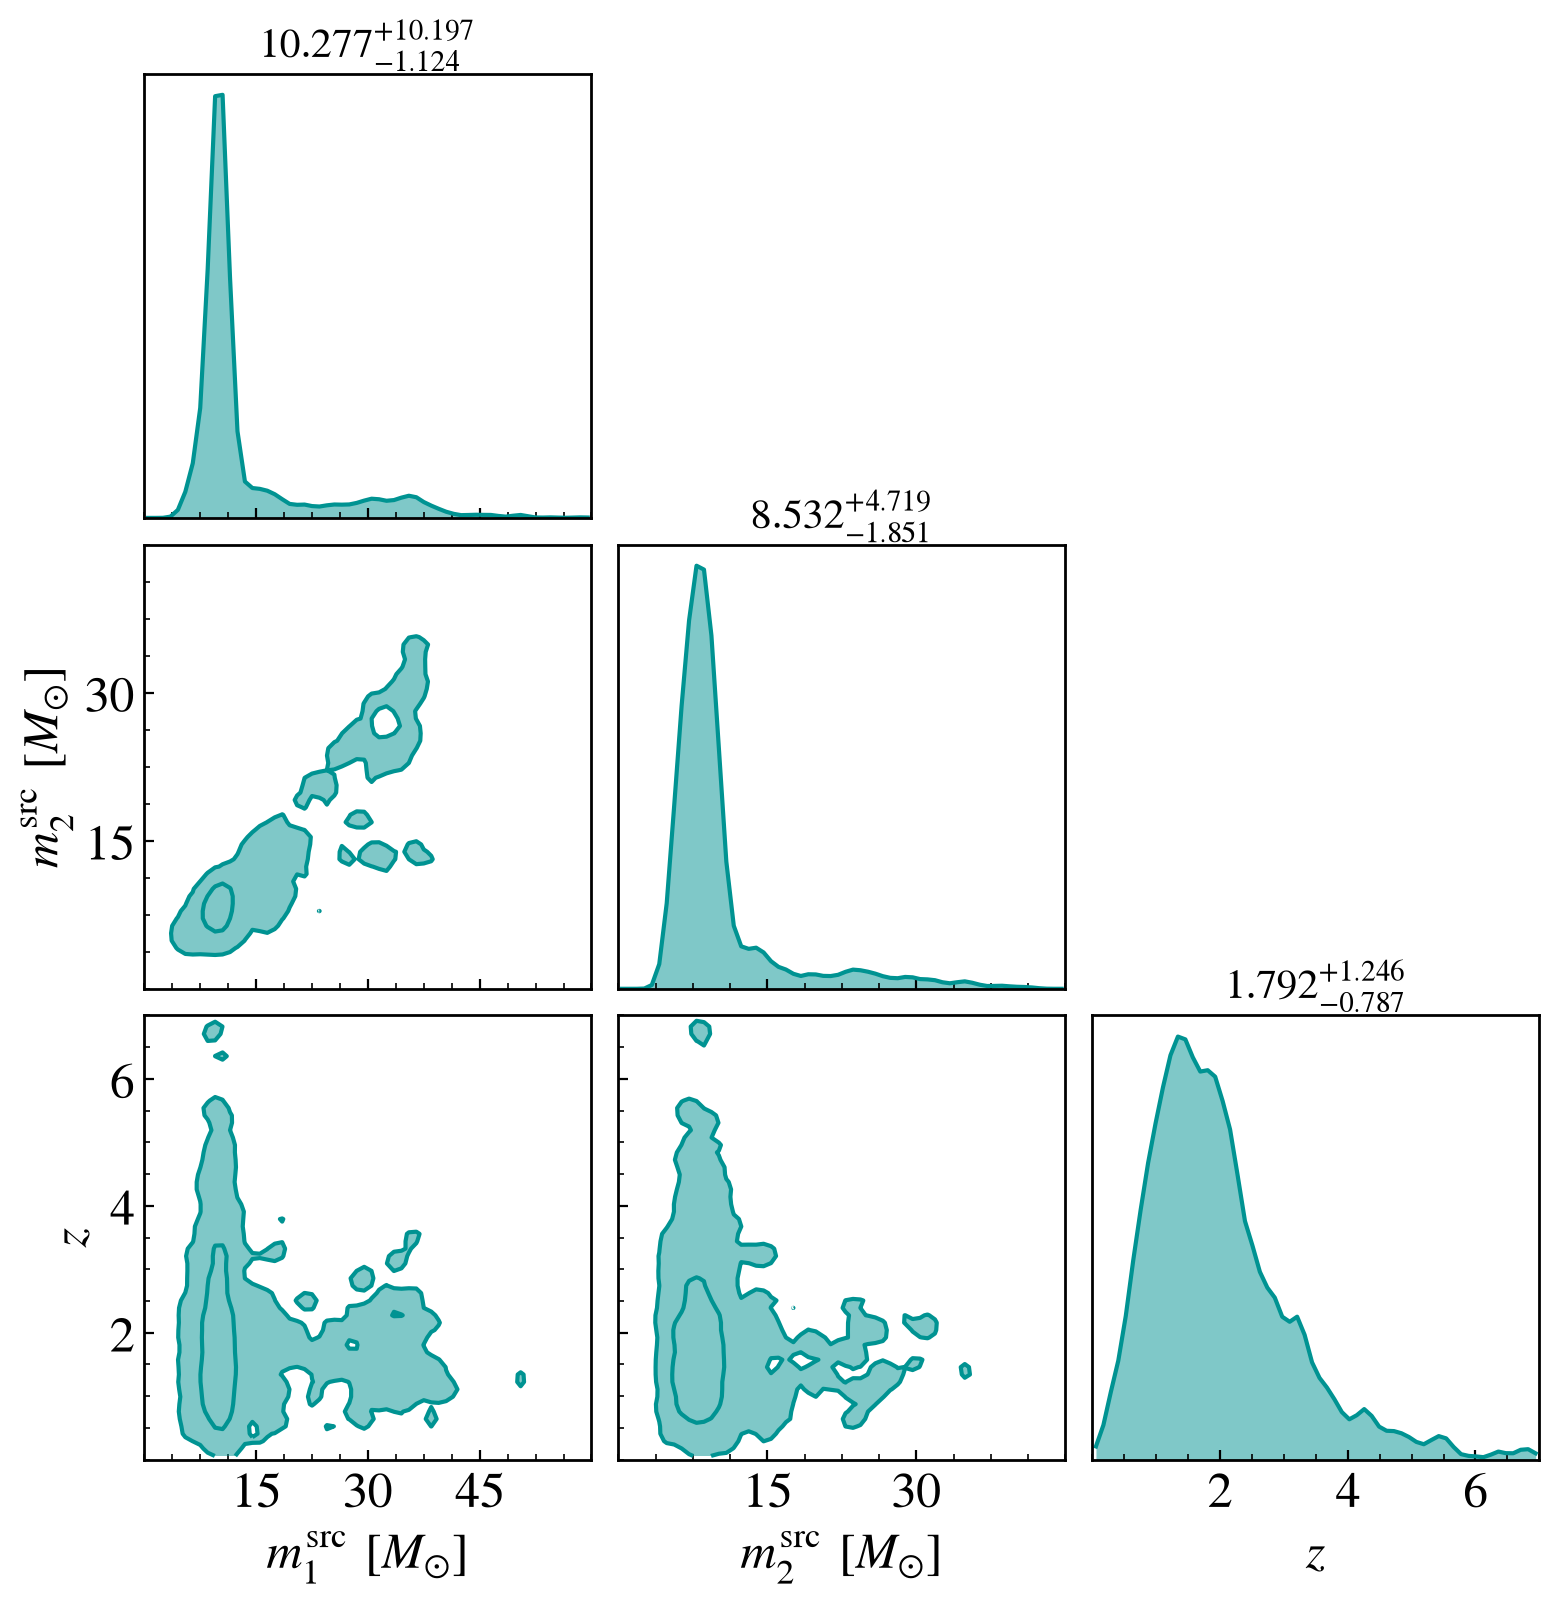

In [6]:
# ── Source-frame masses against redshift ──────────────────────────────────────
# The default panel range is mean +/- 4 sigma, which runs negative for these
# skewed distributions, so the physical ranges are given by hand.
names = ["mass_1_source", "mass_2_source", "redshift"]
span = [(0, 60), (0, 45), (0, 7)]
fig = corner_plot(numpy.column_stack([samples[n] for n in names]), labels=labels_for(names), span=span)

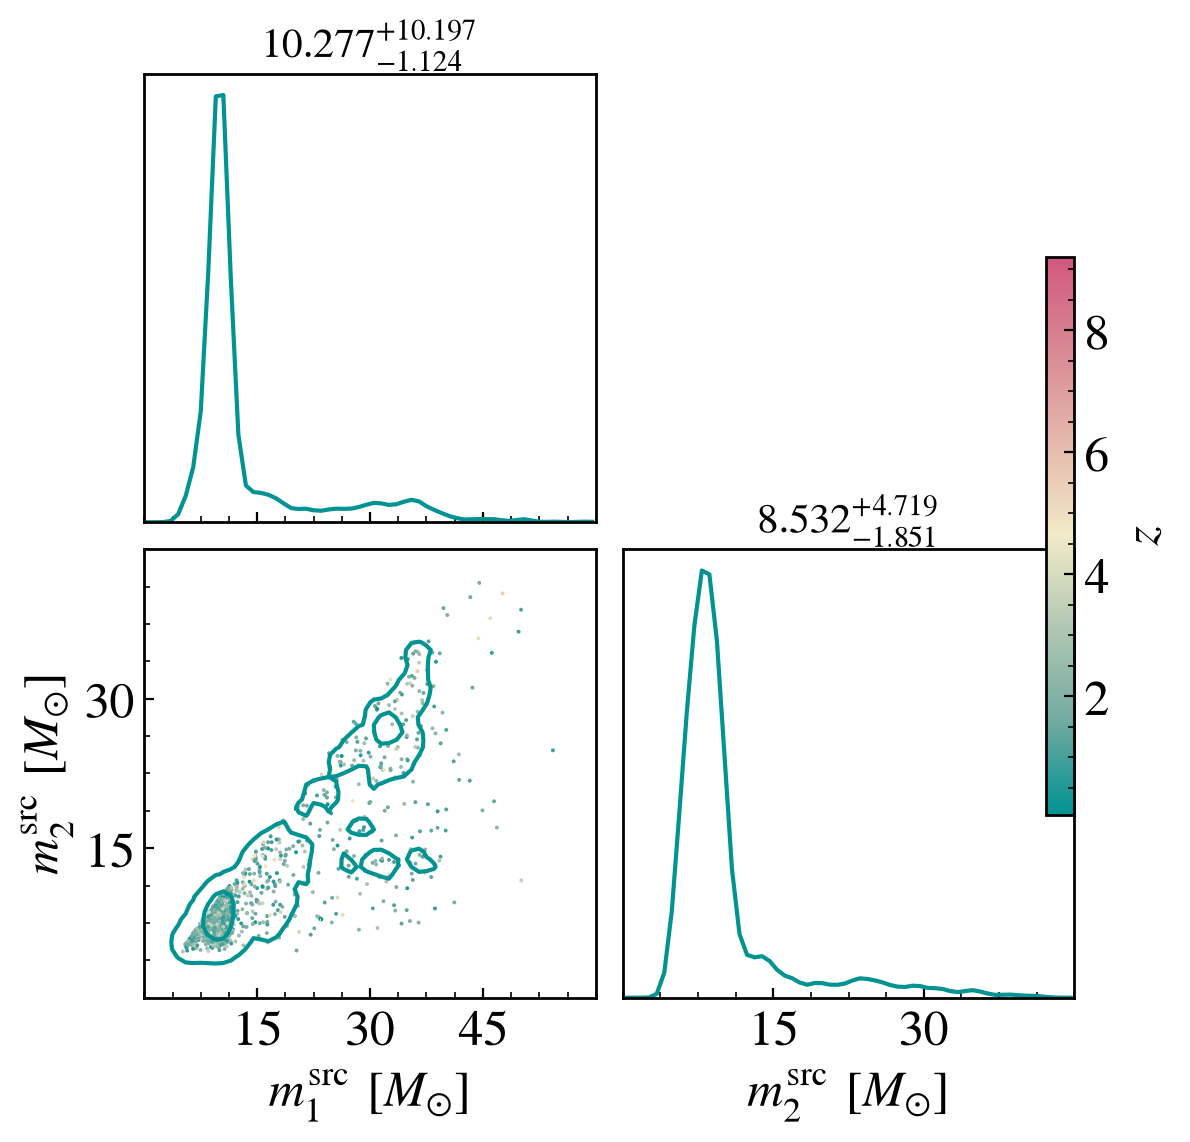

In [7]:
# ── Same masses, each merger coloured by its redshift ─────────────────────────
names = ["mass_1_source", "mass_2_source"]
fig = corner_plot(
    numpy.column_stack([samples[n] for n in names]),
    labels=labels_for(names),
    span=span[:2],
    colour_by=samples["redshift"],
    colour_label=labels_for(["redshift"])[0],
)

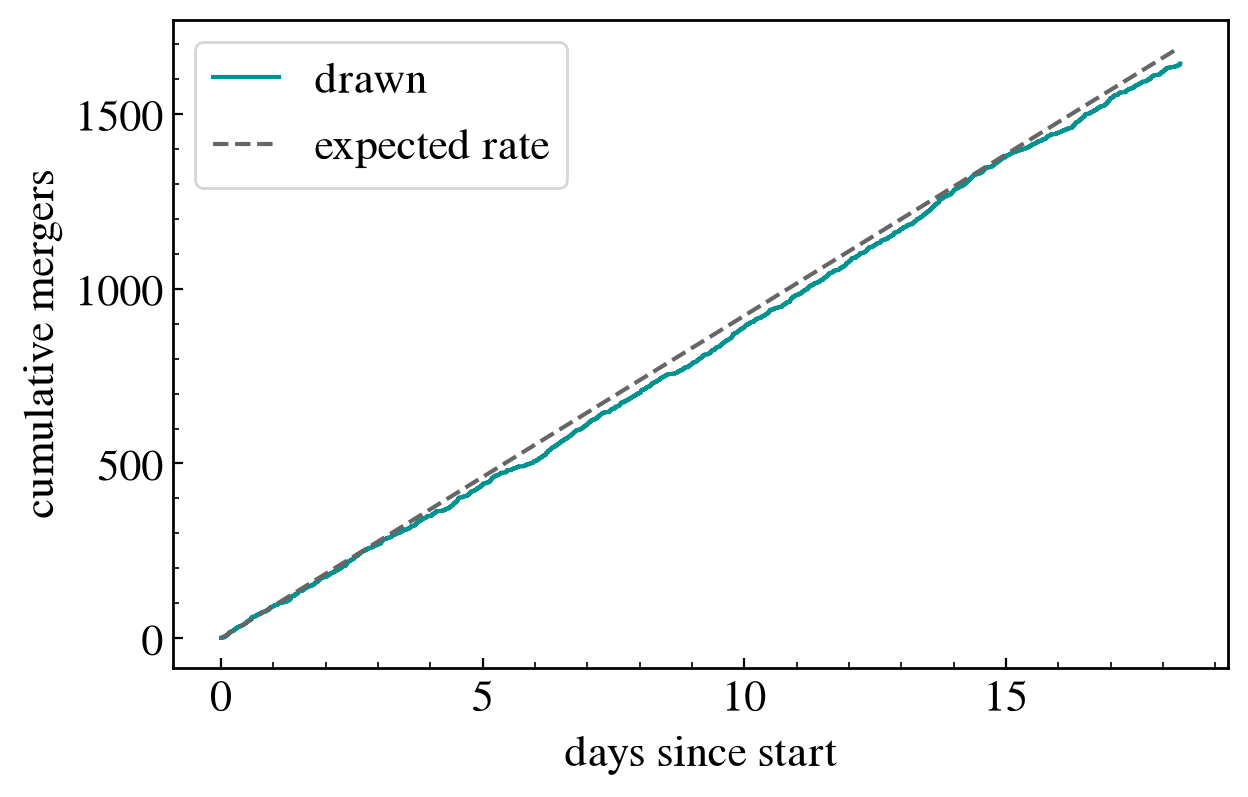

In [8]:
# ── Arrival times: a Poisson process at the predicted rate ────────────────────
days = numpy.sort(samples["geocent_time"] - GPS_START) / 86400
expected = ANALYSIS_TIME / z.average_time_between_signals()

pylab.figure()
pylab.step(days, numpy.arange(1, N + 1), where="post", color=XG_COLOUR, label="drawn")
pylab.plot([0, ANALYSIS_TIME / 86400], [0, expected], "--", color="0.4", label="expected rate")
pylab.xlabel("days since start")
pylab.ylabel("cumulative mergers")
pylab.legend()

The same population from the command line, with the shipped configuration that encodes every default used above:

```bash
gwforge_population --config-file bgp-gwtc5.ini --output-file population.h5 --seed 1234
```

The file `bgp-gwtc5.ini` lives in `GWForge/population/population_configuration_files/`; the output HDF5 holds one dataset per key printed above.